# 05 Associated factors

Future teammate work: analysis of associated factors; preserve observed values and document denominators.

## Function checks on known pairs (Member 3, 14 Nov 2026)

These cells check the functions in `src/associations.py` on pairs whose answer is known in advance. **They are not Q2 results.** The leading predictors for Q2 will be chosen from Member 3's model ranking, after which the association screen will be run.

All functions use observed pairs only (no imputation) and return `estimate`, `n_used` and `missing_pair_fraction`. Only the observed training split is read.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "src"))
from associations import (
    correlation_ratio, cramers_v_bc, group_bootstrap, sparse_groups, spearman_assoc,
)

df = pd.read_csv("../data/processed/observed/training.csv")
print("Training split:", df.shape)

Training split: (308080, 41)


### Spearman: BMI vs WeightInKilograms

Expected: the value in Member 2's EDA (`results/tables/spearman_correlation.csv`, about 0.847) with n = 274,752 pairs (`results/tables/spearman_pair_counts.csv`).

In [2]:
eda_spearman = pd.read_csv("../results/tables/spearman_correlation.csv", index_col="variable")
eda_pairs = pd.read_csv("../results/tables/spearman_pair_counts.csv", index_col="variable")

bmi_weight = spearman_assoc(df["BMI"], df["WeightInKilograms"])
print(bmi_weight)
assert bmi_weight["n_used"] == eda_pairs.loc["BMI", "WeightInKilograms"] == 274752
assert abs(bmi_weight["estimate"] - eda_spearman.loc["BMI", "WeightInKilograms"]) < 1e-9
print("Matches the EDA: rho =", round(bmi_weight["estimate"], 3), "with n =", f"{bmi_weight['n_used']:,}")

{'estimate': 0.8466525103485081, 'n_used': 274752, 'missing_pair_fraction': 0.10817969358608148}
Matches the EDA: rho = 0.847 with n = 274,752


### Cramér's V (bias-corrected): a variable with itself, and with a shuffled copy

Expected: about 1 for `GeneralHealth` with itself, and about 0 for `GeneralHealth` with a randomly shuffled copy of itself (seed 42).

In [3]:
self_v = cramers_v_bc(df["GeneralHealth"], df["GeneralHealth"])
print("With itself:", {k: v for k, v in self_v.items() if k != "table"})
assert abs(self_v["estimate"] - 1) < 1e-9

rng = np.random.default_rng(42)
shuffled = df["GeneralHealth"].copy()
observed = shuffled.notna()
shuffled[observed] = rng.permutation(shuffled[observed].to_numpy())
shuffled_v = cramers_v_bc(df["GeneralHealth"], shuffled)
print("With shuffled copy:", {k: v for k, v in shuffled_v.items() if k != "table"})
assert shuffled_v["estimate"] < 0.01

With itself: {'estimate': 0.9999999999999999, 'n_used': 307335, 'missing_pair_fraction': 0.0024182030641392016}


With shuffled copy:

 {'estimate': 0.0007848742436874935, 'n_used': 307335, 'missing_pair_fraction': 0.0024182030641392016}


### Correlation ratio (eta): BMI by BMI group

`BMI_Group` uses Member 2's definition (`notebooks/03_eda.ipynb`, section 5, "Body mass index (BMI)"). The group is derived from BMI itself, so eta should be high.

In [4]:
bmi_group = pd.cut(
    df["BMI"],
    bins=[0, 18.5, 25, 30, 35, 40, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obesity Class I", "Obesity Class II", "Obesity Class III"],
    right=False,
)
bmi_eta = correlation_ratio(bmi_group, df["BMI"])
print(bmi_eta)
assert bmi_eta["estimate"] > 0.8 and bmi_eta["n_used"] == 274752

{'estimate': 0.9490212584278763, 'n_used': 274752, 'missing_pair_fraction': 0.10817969358608148}


### A constant column gives NaN, not an error

In [5]:
constant = pd.Series(1.0, index=df.index)
constant_checks = {
    "spearman_assoc": spearman_assoc(constant, df["BMI"]),
    "cramers_v_bc": cramers_v_bc(constant, df["Sex"]),
    "correlation_ratio (constant response)": correlation_ratio(df["Sex"], constant),
}
for name, result in constant_checks.items():
    print(name, {k: v for k, v in result.items() if k != "table"})
    assert np.isnan(result["estimate"])

spearman_assoc {'estimate': nan, 'n_used': 274752, 'missing_pair_fraction': 0.10817969358608148}
cramers_v_bc {'estimate': nan, 'n_used': 308080, 'missing_pair_fraction': 0.0}
correlation_ratio (constant response) {'estimate': nan, 'n_used': 308080, 'missing_pair_fraction': 0.0}


### Sparse groups and the group bootstrap

`sparse_groups` should flag the Sex and HadDiabetes combination of Male with pregnancy-only diabetes (15 records; see the clarification in `03_eda.ipynb`). `group_bootstrap` resamples whole `duplicate_group` groups. Here it runs with 100 resamples to keep the notebook quick; the interval should contain the BMI–weight estimate above.

In [6]:
sex_diabetes = df["Sex"] + " | " + df["HadDiabetes"]
sex_diabetes_groups = sparse_groups(sex_diabetes, min_n=30)
display(sex_diabetes_groups)
flagged = sex_diabetes_groups.loc[sex_diabetes_groups["sparse"]]
assert list(flagged["category"]) == ["Male | Yes, but only during pregnancy (female)"]
assert flagged["n"].iloc[0] == 15

bmi_weight_boot = group_bootstrap(
    df[["BMI", "WeightInKilograms", "duplicate_group"]],
    lambda d: spearman_assoc(d["BMI"], d["WeightInKilograms"]),
    n_boot=100,
)
print(bmi_weight_boot)
assert bmi_weight_boot["ci_lower"] <= bmi_weight["estimate"] <= bmi_weight_boot["ci_upper"]

,category,n,sparse
0,"Male | Yes, but only during pregnancy (female)",15,True
1,"Female | Yes, but only during pregnancy (female)",2681,False
2,"Male | No, pre-diabetes or borderline diabetes",3118,False
3,"Female | No, pre-diabetes or borderline diabetes",3906,False
4,Male | Yes,20833,False
5,Female | Yes,21448,False
6,Male | No,120557,False
7,Female | No,134998,False


{'estimate': 0.8466525103485081, 'ci_lower': 0.8453842808265891, 'ci_upper': 0.8476217885275321, 'n_boot_valid': 100, 'n_groups': 307971}


# Q2: What goes together with each leading predictor?

**Question:** which demographic, health and lifestyle variables are most strongly associated with the leading predictors?

The leading predictors come from the model ranking in `results/modelling/top5_handoff_for_q2.csv`. Everything is ranked and chosen on the **training** split; the **validation** split is used only to confirm. The test split is not read. Only observed pairs are used (no imputation), and every score reports `n_used`. These are associations, not causal effects.

## Section A: Setup

Load the plotting library, the split loader and the output folders.

In [7]:
import time

import matplotlib.pyplot as plt
from modelling import load_split

Q2_DIR = Path("../results/q2")
FIG_DIR = Path("../results/figures")
Q2_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

Load the training and validation splits with `load_split` (which refuses the test split) and print their shapes.

In [8]:
train = load_split("training")
valid = load_split("validation")
print("Training:  ", train.shape)
print("Validation:", valid.shape)

Training:   (308080, 41)
Validation: (66016, 41)


Read the five leading predictors from the modelling handoff file and check that they are columns in both splits.

In [9]:
handoff = pd.read_csv("../results/modelling/top5_handoff_for_q2.csv")
LEADING = handoff.sort_values("rank")["feature"].tolist()
print("Leading predictors:", LEADING)
for frame in (train, valid):
    assert set(LEADING) <= set(frame.columns)
print("All five are present in both splits.")

Leading predictors: ['AgeCategory', 'GeneralHealth', 'Sex', 'HadStroke', 'HadKidneyDisease']
All five are present in both splits.


Build the candidate list from the modelling code, so Q1 and Q2 use one consistent set of variables: start from `split_xy(train, drop=POST_DIAGNOSIS_FEATURES)` in `src/modelling.py` (which removes the outcome, its sources, the ID columns, and `ChestScan` and `PneumoVaxEver`, decision-log entry 12), then remove `HeightInMeters` and `WeightInKilograms`, which the shared preprocessor drops because the models use BMI instead. The other leading predictors stay in as candidates; each predictor is only left out of its own list.

In [10]:
from modelling import POST_DIAGNOSIS_FEATURES, split_xy
from preprocessing import EXCLUDED as PREPROCESSOR_EXCLUDED

X_train, _ = split_xy(train, drop=POST_DIAGNOSIS_FEATURES)
NOT_IN_MODELS = ["HeightInMeters", "WeightInKilograms"]   # the models use BMI instead
assert set(NOT_IN_MODELS) <= PREPROCESSOR_EXCLUDED
CANDIDATES = [c for c in X_train.columns if c not in NOT_IN_MODELS]

X_valid, _ = split_xy(valid, drop=POST_DIAGNOSIS_FEATURES)
assert CANDIDATES == [c for c in X_valid.columns if c not in NOT_IN_MODELS]
assert set(LEADING) <= set(CANDIDATES)
assert not {"SleepGroup", "BMI_Group", "PhysicalHealthGroup", "MentalHealthGroup"} & set(CANDIDATES)

print("Removed from the split columns:", [c for c in train.columns if c not in CANDIDATES])
print(len(CANDIDATES), "candidate columns (the five leading predictors included):")
print(CANDIDATES)
assert len(CANDIDATES) == 34

Removed from the split columns: ['row_id', 'duplicate_group', 'ChestScan', 'HeightInMeters', 'WeightInKilograms', 'PneumoVaxEver', 'heart_disease']
34 candidate columns (the five leading predictors included):
['State', 'Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays', 'LastCheckupTime', 'PhysicalActivities', 'SleepHours', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'RaceEthnicityCategory', 'AgeCategory', 'BMI', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']


Classify each candidate as numeric or categorical and print both lists.

In [11]:
NUMERIC = ["BMI", "PhysicalHealthDays", "MentalHealthDays", "SleepHours"]
CATEGORICAL = [c for c in CANDIDATES if c not in NUMERIC]
assert set(NUMERIC) <= set(CANDIDATES)
assert all(pd.api.types.is_numeric_dtype(train[c]) for c in NUMERIC)
print(f"Numeric ({len(NUMERIC)}):", NUMERIC)
print(f"Categorical ({len(CATEGORICAL)}):", CATEGORICAL)

Numeric (4): ['BMI', 'PhysicalHealthDays', 'MentalHealthDays', 'SleepHours']
Categorical (30): ['State', 'Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'RaceEthnicityCategory', 'AgeCategory', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']


Flag the one special column with a note: State is geographic and has many levels.

In [12]:
NOTES = {"State": "geographic; 50+ levels"}
print("State levels in training:", train["State"].nunique())
NOTES

State levels in training: 54


{'State': 'geographic; 50+ levels'}

List the definitional pairs. These are linked by definition, so they tell us nothing new; they stay in the full table but are left out of the top lists.

- **Sex × HadDiabetes**: one level is "Yes, but only during pregnancy (female)".

The Sex × height and Sex × weight pairs (expected body-size difference) no longer arise, because height and weight are not candidates.

I also checked every other leading predictor × candidate pair for a "same question asked twice" link and added none. The closest are GeneralHealth with PhysicalHealthDays / MentalHealthDays, but those ask for a count of bad days in the past 30, not an overall rating, so they are kept.

In [13]:
DEFINITIONAL = {
    ("Sex", "HadDiabetes"): "one level is 'during pregnancy (female)'",
}
assert all(c in CANDIDATES for _, c in DEFINITIONAL)
pd.Series(DEFINITIONAL, name="reason").rename_axis(["predictor", "candidate"]).to_frame()

,,reason
predictor,candidate,
Sex,HadDiabetes,one level is 'during pregnancy (female)'


**Outcome (section A):** Both splits load with 41 columns: 308,080 training rows and 66,016 validation rows. All five leading predictors are present. The candidates are the **34 model features**. `split_xy` removes the outcome, the two ID columns, ChestScan and PneumoVaxEver; height and weight are removed because the models use BMI. The 34 are 4 numeric (BMI, PhysicalHealthDays, MentalHealthDays, SleepHours) and 30 categorical, and they include the five leading predictors. State (54 levels) is the only column with a note. One pair is definitional: Sex × HadDiabetes.

## Section B: Association scores on the training split

The main score is **bias-corrected Cramér's V** for a categorical candidate and the **correlation ratio (eta)** for a numeric candidate, with the predictor as the groups. Both run from 0 (no link) to 1 and have no sign.

Where both columns are ordered, Spearman's rho is added as a direction measure. These are the explicit order maps (higher number = older, healthier, more recent check-up, more teeth removed):

In [14]:
AGE_LEVELS = sorted(train["AgeCategory"].dropna().unique(), key=lambda s: int(s.split()[1]))
ORDINAL_MAPS = {
    "AgeCategory": {level: i + 1 for i, level in enumerate(AGE_LEVELS)},
    "GeneralHealth": {"Poor": 1, "Fair": 2, "Good": 3, "Very good": 4, "Excellent": 5},
    "LastCheckupTime": {
        "5 or more years ago": 1,
        "Within past 5 years (2 years but less than 5 years ago)": 2,
        "Within past 2 years (1 year but less than 2 years ago)": 3,
        "Within past year (anytime less than 12 months ago)": 4,
    },
    "RemovedTeeth": {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3},
}
for col, mapping in ORDINAL_MAPS.items():
    for frame in (train, valid):
        assert set(frame[col].dropna().unique()) == set(mapping), col
    print(col)
    for level, rank in mapping.items():
        print(f"    {rank:>2}  {level}")
print("Numeric columns are used as they are:", NUMERIC)

AgeCategory
     1  Age 18 to 24
     2  Age 25 to 29
     3  Age 30 to 34
     4  Age 35 to 39
     5  Age 40 to 44
     6  Age 45 to 49
     7  Age 50 to 54
     8  Age 55 to 59
     9  Age 60 to 64
    10  Age 65 to 69
    11  Age 70 to 74
    12  Age 75 to 79
    13  Age 80 or older
GeneralHealth
     1  Poor
     2  Fair
     3  Good
     4  Very good
     5  Excellent


LastCheckupTime


     1  5 or more years ago
     2  Within past 5 years (2 years but less than 5 years ago)
     3  Within past 2 years (1 year but less than 2 years ago)
     4  Within past year (anytime less than 12 months ago)


RemovedTeeth
     0  None of them
     1  1 to 5
     2  6 or more, but not all
     3  All
Numeric columns are used as they are: ['BMI', 'PhysicalHealthDays', 'MentalHealthDays', 'SleepHours']


Define one function that scores a pair with the right measure, and one that adds Spearman when both columns are ordered.

In [15]:
def measure_for(candidate):
    return "eta" if candidate in NUMERIC else "V"


def score_pair(frame, predictor, candidate):
    """Main association score (observed pairs only), as returned by src/associations.py."""
    if candidate in NUMERIC:
        return correlation_ratio(frame[predictor], frame[candidate])
    return cramers_v_bc(frame[predictor], frame[candidate])


def is_ordered(col):
    return col in ORDINAL_MAPS or col in NUMERIC


def spearman_pair(frame, predictor, candidate):
    """Spearman rho with the explicit order maps, or None when either column is not ordered."""
    if not (is_ordered(predictor) and is_ordered(candidate)):
        return None
    mapping = {**ORDINAL_MAPS.get(predictor, {}), **ORDINAL_MAPS.get(candidate, {})}
    return spearman_assoc(frame[predictor], frame[candidate], ordinal_map=mapping or None)

Describe sparse levels (fewer than 30 observed pairs). For a categorical candidate the candidate's levels are checked; for a numeric candidate the eta groups are the predictor's levels, so those are checked instead.

In [16]:
def sparse_text(frame, predictor, candidate, min_n=30):
    pairs = frame[[predictor, candidate]].dropna()
    column = predictor if candidate in NUMERIC else candidate
    table = sparse_groups(pairs[column], min_n=min_n)
    flagged = table.loc[table["sparse"]]
    return "; ".join(f"{row.category} (n={row.n})" for row in flagged.itertuples())

Score every leading predictor against every other candidate on the training split.

In [17]:
start = time.time()
rows = []
for predictor in LEADING:
    for candidate in CANDIDATES:
        if candidate == predictor:
            continue
        main = score_pair(train, predictor, candidate)
        rho = spearman_pair(train, predictor, candidate)
        rows.append({
            "predictor": predictor,
            "candidate": candidate,
            "candidate_type": "numeric" if candidate in NUMERIC else "categorical",
            "measure": measure_for(candidate),
            "score_train": main["estimate"],
            "n_used_train": main["n_used"],
            "missing_pair_fraction_train": main["missing_pair_fraction"],
            "spearman_train": rho["estimate"] if rho else np.nan,
            "sparse_levels": sparse_text(train, predictor, candidate),
            "between_leading": candidate in LEADING,
            "definitional": (predictor, candidate) in DEFINITIONAL,
            "note": NOTES.get(candidate, ""),
        })
assoc = pd.DataFrame(rows)
print(f"{len(assoc)} pairs scored in {time.time() - start:.0f} s")
print("Pairs by measure:", assoc["measure"].value_counts().to_dict())
print("Pairs with Spearman:", int(assoc["spearman_train"].notna().sum()))
print("Smallest n_used:", int(assoc["n_used_train"].min()), "| largest missing-pair fraction:",
      round(assoc["missing_pair_fraction_train"].max(), 3))
assert assoc["score_train"].notna().all()

165 pairs scored in 33 s
Pairs by measure: {'V': 145, 'eta': 20}
Pairs with Spearman: 14
Smallest n_used: 247381 | largest missing-pair fraction: 0.197


List the pairs that have sparse levels, so they can be read with care.

In [18]:
assoc.loc[assoc["sparse_levels"] != "", ["predictor", "candidate", "sparse_levels"]]

,predictor,candidate,sparse_levels


Show the top 10 candidates for each predictor by training score, leaving out definitional pairs.

In [19]:
SHOW = ["candidate", "measure", "score_train", "n_used_train", "spearman_train", "between_leading", "note"]
ranked = (assoc.loc[~assoc["definitional"]]
          .sort_values(["predictor", "score_train"], ascending=[True, False]))
for predictor in LEADING:
    print(f"\n=== {predictor} ===")
    top10 = ranked.loc[ranked["predictor"] == predictor, SHOW].head(10)
    print(top10.round(3).to_string(index=False))


=== AgeCategory ===
          candidate measure  score_train  n_used_train  spearman_train  between_leading note
       HadArthritis       V        0.400        300474             NaN            False     
         HIVTesting       V        0.310        258448             NaN            False     
       FluVaxLast12       V        0.294        271253             NaN            False     
      HadSkinCancer       V        0.259        300132             NaN            False     
  DifficultyWalking       V        0.258        286536             NaN            False     
DeafOrHardOfHearing       V        0.249        288746             NaN            False     
       RemovedTeeth       V        0.220        294787           0.370            False     
   HighRiskLastYear       V        0.214        268848             NaN            False     
   MentalHealthDays     eta        0.184        296165          -0.263            False     
                BMI     eta        0.172        2

**Outcome (section B):** 165 pairs were scored (145 with V, 20 with eta; 14 also have Spearman). Every pair has at least 247,381 observed pairs, the largest missing-pair fraction is 0.197, and no candidate level has fewer than 30 pairs. The three strongest non-definitional links per predictor are:

- **AgeCategory:** HadArthritis (V = 0.400), HIVTesting (V = 0.310), FluVaxLast12 (V = 0.294).
- **GeneralHealth:** PhysicalHealthDays (eta = 0.590; Spearman = −0.422, so a better rating goes with fewer bad physical-health days), DifficultyWalking (V = 0.453), DifficultyErrands (V = 0.366).
- **Sex:** HadDepressiveDisorder (V = 0.132), LastCheckupTime (V = 0.108), TetanusLast10Tdap (V = 0.108). Every Sex link is weak (V ≤ 0.132).
- **HadStroke:** GeneralHealth (V = 0.179), DifficultyWalking (V = 0.174), AgeCategory (V = 0.147).
- **HadKidneyDisease:** GeneralHealth (V = 0.192), HadDiabetes (V = 0.169), DifficultyWalking (V = 0.161).

V and eta both run from 0 to 1, but they are not on exactly the same scale: eta compares group means of a number, V summarises a whole table. Compare links within one measure where possible; GeneralHealth's eta of 0.590 should not be read as strictly "stronger" than its V of 0.453.

## Section C: Uncertainty for the strongest links (training)

Take the top 5 non-definitional candidates for each predictor (25 links in all).

In [20]:
top = ranked.groupby("predictor", sort=False).head(5).copy()
top["rank_train"] = top.groupby("predictor").cumcount() + 1
top = top.set_index("predictor").loc[LEADING].reset_index()
assert len(top) == 25
top[["predictor", "rank_train", "candidate", "measure", "score_train"]].round(3)

,predictor,rank_train,candidate,measure,score_train
0,AgeCategory,1,HadArthritis,V,0.400
1,AgeCategory,2,HIVTesting,V,0.310
2,AgeCategory,3,FluVaxLast12,V,0.294
3,AgeCategory,4,HadSkinCancer,V,0.259
4,AgeCategory,5,DifficultyWalking,V,0.258
5,GeneralHealth,1,PhysicalHealthDays,eta,0.590
6,GeneralHealth,2,DifficultyWalking,V,0.453
7,GeneralHealth,3,DifficultyErrands,V,0.366
8,GeneralHealth,4,DifficultyDressingBathing,V,0.338
9,GeneralHealth,5,MentalHealthDays,eta,0.298


Run a group bootstrap for each of the 25 scores: 200 resamples of whole `duplicate_group` groups, seed 42, 95% percentile interval. This takes about 12 minutes.

In [21]:
N_BOOT = 200
start = time.time()
boot_rows = []
for row in top.itertuples():
    p, c = row.predictor, row.candidate
    result = group_bootstrap(
        train[[p, c, "duplicate_group"]],
        lambda d, p=p, c=c: score_pair(d, p, c),
        group_col="duplicate_group", n_boot=N_BOOT, seed=42,
    )
    assert abs(result["estimate"] - row.score_train) < 1e-12
    boot_rows.append({"predictor": p, "candidate": c, "ci_low_train": result["ci_lower"],
                      "ci_high_train": result["ci_upper"], "n_boot_valid": result["n_boot_valid"]})
boot = pd.DataFrame(boot_rows)
top = top.merge(boot, on=["predictor", "candidate"])
print(f"{N_BOOT} resamples x {len(top)} links in {(time.time() - start) / 60:.1f} min")
print("Valid resamples per link:", sorted(top["n_boot_valid"].unique()))

200 resamples x 25 links in 11.7 min
Valid resamples per link: [np.int64(200)]


Show each link with its interval.

In [22]:
top[["predictor", "rank_train", "candidate", "measure", "score_train", "ci_low_train", "ci_high_train"]].round(4)

,predictor,rank_train,candidate,measure,score_train,ci_low_train,ci_high_train
0,AgeCategory,1,HadArthritis,V,0.3996,0.3966,0.4024
1,AgeCategory,2,HIVTesting,V,0.3098,0.3070,0.3132
2,AgeCategory,3,FluVaxLast12,V,0.2936,0.2905,0.2970
3,AgeCategory,4,HadSkinCancer,V,0.2587,0.2547,0.2620
4,AgeCategory,5,DifficultyWalking,V,0.2585,0.2551,0.2611
5,GeneralHealth,1,PhysicalHealthDays,eta,0.5897,0.5860,0.5936
6,GeneralHealth,2,DifficultyWalking,V,0.4531,0.4499,0.4572
7,GeneralHealth,3,DifficultyErrands,V,0.3662,0.3606,0.3718
8,GeneralHealth,4,DifficultyDressingBathing,V,0.3380,0.3329,0.3451
9,GeneralHealth,5,MentalHealthDays,eta,0.2980,0.2936,0.3021


Check which neighbouring links (same predictor, same measure) have overlapping intervals, meaning their order cannot be told apart.

In [23]:
overlaps = []
for predictor, group in top.groupby("predictor", sort=False):
    group = group.reset_index(drop=True)
    for i in range(len(group)):
        for j in range(i + 1, len(group)):
            a, b = group.loc[i], group.loc[j]
            if a["ci_low_train"] <= b["ci_high_train"] and b["ci_low_train"] <= a["ci_high_train"]:
                overlaps.append({"predictor": predictor,
                                 "link_a": f"{a['candidate']} ({a['measure']})",
                                 "link_b": f"{b['candidate']} ({b['measure']})",
                                 "same_measure": a["measure"] == b["measure"]})
overlaps = pd.DataFrame(overlaps, columns=["predictor", "link_a", "link_b", "same_measure"])
print(len(overlaps), "overlapping pairs out of", 5 * 10)
overlaps

10 overlapping pairs out of 50


,predictor,link_a,link_b,same_measure
0,AgeCategory,HadSkinCancer (V),DifficultyWalking (V),True
1,Sex,LastCheckupTime (V),TetanusLast10Tdap (V),True
2,Sex,LastCheckupTime (V),AlcoholDrinkers (V),True
3,Sex,TetanusLast10Tdap (V),AlcoholDrinkers (V),True
4,Sex,AlcoholDrinkers (V),HadArthritis (V),True
5,HadStroke,GeneralHealth (V),DifficultyWalking (V),True
6,HadStroke,AgeCategory (V),RemovedTeeth (V),True
7,HadStroke,RemovedTeeth (V),PhysicalHealthDays (eta),False
8,HadKidneyDisease,HadDiabetes (V),DifficultyWalking (V),True
9,HadKidneyDisease,AgeCategory (V),PhysicalHealthDays (eta),False


Check whether the point estimate lies inside its own percentile interval (it can sit just outside for weak V, because resampling adds a little upward bias).

In [24]:
inside = top["score_train"].between(top["ci_low_train"], top["ci_high_train"])
print("Point estimate inside its interval:", int(inside.sum()), "of", len(top))
top.loc[~inside, ["predictor", "candidate", "score_train", "ci_low_train", "ci_high_train"]].round(4)

Point estimate inside its interval: 25 of 25


,predictor,candidate,score_train,ci_low_train,ci_high_train


**Outcome (section C):** All 25 intervals use 200 valid resamples (11.7 minutes in total). They are narrow, 0.006 to 0.012 wide, and each contains its own point estimate. GeneralHealth's top 5 are fully separated. 10 of the 50 within-predictor pairs overlap, so their order is not reliable:

- **AgeCategory:** HadSkinCancer (0.259) and DifficultyWalking (0.258) are tied at ranks 4–5.
- **Sex:** ranks 2 to 5 (LastCheckupTime, TetanusLast10Tdap, AlcoholDrinkers, HadArthritis; V 0.100–0.108) cannot be told apart; only HadDepressiveDisorder (0.132) is clearly first.
- **HadStroke:** GeneralHealth (0.179) and DifficultyWalking (0.174) are tied, as are AgeCategory (0.147) and RemovedTeeth (0.142). RemovedTeeth (V) also overlaps PhysicalHealthDays (eta 0.137), but those use different measures.
- **HadKidneyDisease:** HadDiabetes (0.169) and DifficultyWalking (0.161) overlap. AgeCategory (V) and PhysicalHealthDays (eta), both 0.143, also overlap, but use different measures.

## Section D: Confirm on the validation split

Recompute the same 25 scores on the validation split with the same functions.

In [25]:
valid_rows = []
for row in top.itertuples():
    result = score_pair(valid, row.predictor, row.candidate)
    valid_rows.append({"predictor": row.predictor, "candidate": row.candidate,
                       "score_valid": result["estimate"], "n_used_valid": result["n_used"]})
top = top.merge(pd.DataFrame(valid_rows), on=["predictor", "candidate"])
print("Validation n_used ranges from", top["n_used_valid"].min(), "to", top["n_used_valid"].max())

Validation n_used ranges from 53718 to 65685


Apply the confirmation rule and print it.

In [26]:
TOLERANCE = 0.02
print(f"Rule: a link is confirmed if |score_valid - score_train| <= {TOLERANCE}, "
      "or score_valid lies inside the training 95% bootstrap interval.")
top["abs_diff"] = (top["score_valid"] - top["score_train"]).abs()
top["within_tolerance"] = top["abs_diff"] <= TOLERANCE
top["inside_train_ci"] = top["score_valid"].between(top["ci_low_train"], top["ci_high_train"])
top["confirmed"] = top["within_tolerance"] | top["inside_train_ci"]
print("Confirmed:", int(top["confirmed"].sum()), "of", len(top))

Rule: a link is confirmed if |score_valid - score_train| <= 0.02, or score_valid lies inside the training 95% bootstrap interval.
Confirmed: 25 of 25


Show the 25 links side by side.

In [27]:
top[["predictor", "candidate", "measure", "score_train", "ci_low_train", "ci_high_train",
     "score_valid", "abs_diff", "inside_train_ci", "confirmed"]].round(4)

,predictor,candidate,measure,score_train,ci_low_train,ci_high_train,score_valid,abs_diff,inside_train_ci,confirmed
0,AgeCategory,HadArthritis,V,0.3996,0.3966,0.4024,0.3942,0.0054,False,True
1,AgeCategory,HIVTesting,V,0.3098,0.3070,0.3132,0.3015,0.0084,False,True
2,AgeCategory,FluVaxLast12,V,0.2936,0.2905,0.2970,0.2886,0.0050,False,True
3,AgeCategory,HadSkinCancer,V,0.2587,0.2547,0.2620,0.2532,0.0056,False,True
4,AgeCategory,DifficultyWalking,V,0.2585,0.2551,0.2611,0.2553,0.0032,True,True
5,GeneralHealth,PhysicalHealthDays,eta,0.5897,0.5860,0.5936,0.5882,0.0015,True,True
6,GeneralHealth,DifficultyWalking,V,0.4531,0.4499,0.4572,0.4615,0.0085,False,True
7,GeneralHealth,DifficultyErrands,V,0.3662,0.3606,0.3718,0.3688,0.0026,True,True
8,GeneralHealth,DifficultyDressingBathing,V,0.3380,0.3329,0.3451,0.3419,0.0039,True,True
9,GeneralHealth,MentalHealthDays,eta,0.2980,0.2936,0.3021,0.2962,0.0018,True,True


List any link that is not confirmed.

In [28]:
top.loc[~top["confirmed"], ["predictor", "candidate", "score_train", "score_valid", "abs_diff"]]

,predictor,candidate,score_train,score_valid,abs_diff


Merge the section C and D results into the full table and save it as `results/q2/q2_associations.csv` (training scores for every pair; intervals and validation scores for the top 25).

In [29]:
ADDED = ["predictor", "candidate", "rank_train", "ci_low_train", "ci_high_train", "n_boot_valid",
         "score_valid", "n_used_valid", "confirmed"]
full = assoc.merge(top[ADDED], on=["predictor", "candidate"], how="left")
full["top5"] = full["rank_train"].notna()
full["rank_train"] = full["rank_train"].astype("Int64")
full["n_boot_valid"] = full["n_boot_valid"].astype("Int64")
full["n_used_valid"] = full["n_used_valid"].astype("Int64")
full["confirmed"] = full["confirmed"].astype("boolean")
full = full.sort_values(["predictor", "score_train"], ascending=[True, False]).reset_index(drop=True)
full.to_csv(Q2_DIR / "q2_associations.csv", index=False)
print(full.shape, "->", Q2_DIR / "q2_associations.csv")

(165, 20) -> ..\results\q2\q2_associations.csv


**Outcome (section D):** All **25 of 25** links are confirmed on the validation split (n_used 53,718 to 65,685). 17 validation scores fall inside the training interval; the other 8 are within 0.02 of the training score. The largest change is HadKidneyDisease × AgeCategory, 0.143 on training and 0.155 on validation (difference 0.011). The next largest is GeneralHealth × DifficultyWalking (0.453 → 0.462, difference 0.009). No link failed. The order within each predictor holds on validation except for two swaps between links whose training intervals overlap: AgeCategory × DifficultyWalking (0.255) moves just above HadSkinCancer (0.253), and Sex × TetanusLast10Tdap (0.107) just above LastCheckupTime (0.105).

## Section E: Describing what each strong link looks like

Scores say how strong a link is, not which way it goes. Each confirmed top link gets a small profile on the training split, using observed pairs only:

- binary predictor (Sex, HadStroke, HadKidneyDisease) × categorical candidate: the share of every candidate level in each group (men vs women; Yes vs No);
- ordered predictor (AgeCategory, GeneralHealth) × categorical candidate: the share of the most informative level at each predictor level, which is "Yes" when the candidate has it, otherwise the level whose share changes most;
- any predictor × numeric candidate: median and mean at each predictor level.

AgeCategory is grouped into 18–39, 40–64 and 65+ (the bands in notebook 06), both as a predictor and as a candidate.

Define the age bands and the display order for each predictor's levels.

In [30]:
BANDS = ["18-39", "40-64", "65+"]


def age_band(category):
    if pd.isna(category):
        return np.nan
    low = int(category.split()[1])          # "Age 18 to 24" -> 18, "Age 80 or older" -> 80
    return "18-39" if low < 40 else ("40-64" if low < 65 else "65+")


LEVEL_ORDER = {
    "AgeCategory": BANDS,
    "GeneralHealth": list(ORDINAL_MAPS["GeneralHealth"]),
    "Sex": ["Male", "Female"],
    "HadStroke": ["Yes", "No"],
    "HadKidneyDisease": ["Yes", "No"],
}


def readable(frame, col):
    """Column values for display: AgeCategory becomes its band."""
    return frame[col].map(age_band) if col == "AgeCategory" else frame[col]

Define the profile function. It returns long-format rows: predictor, candidate, predictor_level, candidate_level_or_stat, value (percent or the numeric unit), n.

In [31]:
def profile(frame, predictor, candidate):
    pairs = frame[[predictor, candidate]].dropna()
    p_level = readable(pairs, predictor)
    order = LEVEL_ORDER[predictor]
    n = p_level.value_counts().reindex(order)
    out = []
    if candidate in NUMERIC:
        stats = pairs[candidate].groupby(p_level).agg(["median", "mean"]).reindex(order)
        for level in order:
            for stat in ("median", "mean"):
                out.append((level, stat, stats.loc[level, stat], n[level]))
    else:
        shares = pd.crosstab(p_level, readable(pairs, candidate), normalize="index").reindex(order) * 100
        if predictor in ("AgeCategory", "GeneralHealth"):
            spread = shares.max() - shares.min()
            keep = ["Yes"] if "Yes" in shares.columns else [spread.idxmax()]
        else:
            keep = list(shares.columns)
        for level in order:
            for c_level in keep:
                out.append((level, f"{c_level} (%)", shares.loc[level, c_level], n[level]))
    return pd.DataFrame(out, columns=["predictor_level", "candidate_level_or_stat", "value", "n"]).assign(
        predictor=predictor, candidate=candidate)

Build the profiles for every confirmed top link and save them as `results/q2/q2_link_profiles.csv`.

In [32]:
confirmed_links = top.loc[top["confirmed"]]
profiles = pd.concat([profile(train, r.predictor, r.candidate) for r in confirmed_links.itertuples()],
                     ignore_index=True)
profiles = profiles[["predictor", "candidate", "predictor_level", "candidate_level_or_stat", "value", "n"]]
profiles["n"] = profiles["n"].astype(int)
profiles.to_csv(Q2_DIR / "q2_link_profiles.csv", index=False)
print(len(confirmed_links), "links,", len(profiles), "rows ->", Q2_DIR / "q2_link_profiles.csv")

25 links, 142 rows -> ..\results\q2\q2_link_profiles.csv


Print the profiles in a wide, readable form (one block per predictor). Shares are percentages of people at that predictor level; numeric rows are in the column's own unit.

In [33]:
for predictor in LEADING:
    block = profiles.loc[profiles["predictor"] == predictor]
    if block.empty:
        continue
    wide = block.pivot_table(index=["candidate", "candidate_level_or_stat"], columns="predictor_level",
                             values="value", sort=False)[LEVEL_ORDER[predictor]]
    print(f"\n=== {predictor} (n per level: "
          f"{block.groupby('predictor_level')['n'].first().reindex(LEVEL_ORDER[predictor]).to_dict()}) ===")
    print(wide.round(1).to_string())


=== AgeCategory (n per level: {'18-39': 71476, '40-64': 119620, '65+': 109378}) ===
predictor_level                            18-39  40-64   65+
candidate         candidate_level_or_stat                    
HadArthritis      Yes (%)                    7.6   31.8  54.2
HIVTesting        Yes (%)                   42.1   44.2  18.1
FluVaxLast12      Yes (%)                   35.1   47.1  69.9
HadSkinCancer     Yes (%)                    0.7    5.0  16.3
DifficultyWalking Yes (%)                    3.7   14.7  25.4

=== GeneralHealth (n per level: {'Poor': 12786, 'Fair': 39221, 'Good': 96811, 'Very good': 101978, 'Excellent': 49418}) ===
predictor_level                                    Poor  Fair  Good  Very good  Excellent
candidate                 candidate_level_or_stat                                        
PhysicalHealthDays        median                   30.0   5.0   0.0        0.0        0.0
                          mean                     23.6  10.9   3.5        1.7        

Figure 1: one panel per predictor with its top 5 links, the training score and its 95% interval; blue = confirmed on validation, grey = not confirmed.

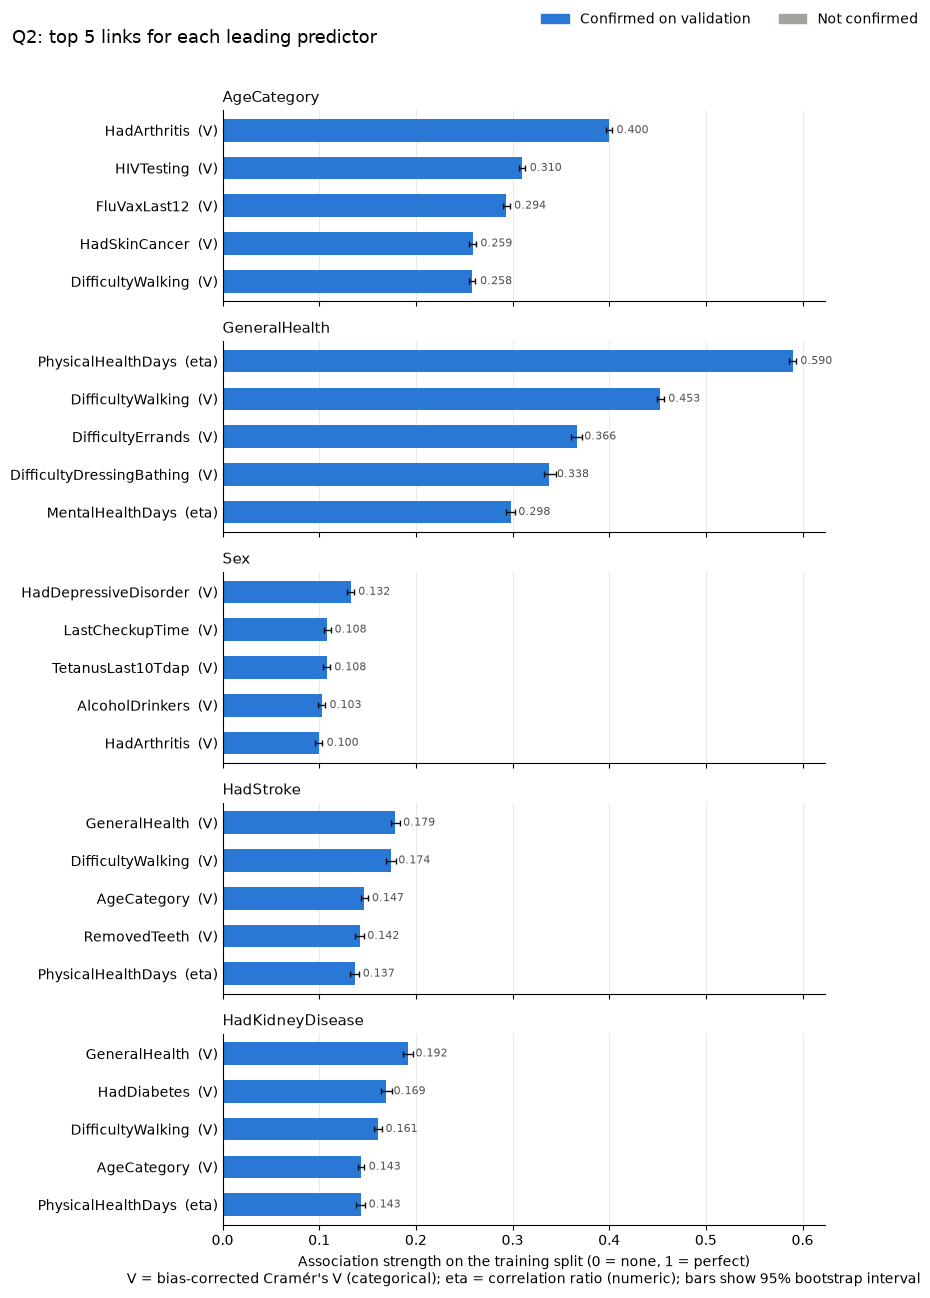

In [34]:
BLUE, GREY, INK, MUTED = "#2a78d6", "#a3a29d", "#0b0b0b", "#52514e"
MEASURE_NAME = {"V": "V", "eta": "eta"}

fig, axes = plt.subplots(5, 1, figsize=(8.5, 13), sharex=True)
for ax, predictor in zip(axes, LEADING):
    links = top.loc[top["predictor"] == predictor].sort_values("score_train")
    y = np.arange(len(links))
    colours = [BLUE if ok else GREY for ok in links["confirmed"]]
    err = [links["score_train"] - links["ci_low_train"], links["ci_high_train"] - links["score_train"]]
    ax.barh(y, links["score_train"], color=colours, height=0.6)
    ax.errorbar(links["score_train"], y, xerr=np.clip(err, 0, None), fmt="none", ecolor=INK, elinewidth=1, capsize=2)
    ax.set_yticks(y, [f"{c}  ({MEASURE_NAME[m]})" for c, m in zip(links["candidate"], links["measure"])])
    for yi, score in zip(y, links["score_train"]):
        ax.text(score + 0.008, yi, f"{score:.3f}", va="center", fontsize=8, color=MUTED)
    ax.set_title(predictor, loc="left", fontsize=11, color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.6)
    ax.set_axisbelow(True)
axes[-1].set_xlabel("Association strength on the training split (0 = none, 1 = perfect)\n"
                    "V = bias-corrected Cramér's V (categorical); eta = correlation ratio (numeric); bars show 95% bootstrap interval")
handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREY)]
fig.legend(handles, ["Confirmed on validation", "Not confirmed"], loc="upper right", frameon=False, ncol=2)
fig.suptitle("Q2: top 5 links for each leading predictor", x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIG_DIR / "q01_top_links.png", dpi=150, bbox_inches="tight")
plt.show()

Choose the four links for figure 2 from the data. The rule: among confirmed links to a categorical candidate that is **not** another leading predictor and is not State, measure the gap (ignoring the "No" level, which mirrors "Yes") in percentage points between the highest and lowest share across predictor levels. Then go down the list from the largest gap and take a link only if neither its predictor nor its candidate is already shown, until there are four (so the panels show four different predictors and four different candidates).

In [35]:
shares = profiles.loc[profiles["candidate_level_or_stat"].str.endswith("(%)")]
# "No" mirrors "Yes" for a yes/no candidate, so only the other levels compete
candidates_shares = shares.loc[shares["candidate_level_or_stat"] != "No (%)"]
eligible = confirmed_links.loc[~confirmed_links["between_leading"] & (confirmed_links["note"] == "")
                               & (confirmed_links["candidate_type"] == "categorical"), ["predictor", "candidate"]]
gaps = (candidates_shares.merge(eligible, on=["predictor", "candidate"])
        .groupby(["predictor", "candidate", "candidate_level_or_stat"])["value"]
        .agg(lambda v: v.max() - v.min()).rename("gap_pp").reset_index()
        .sort_values("gap_pp", ascending=False))
picked, used_p, used_c = [], set(), set()
for row in gaps.itertuples():
    if row.predictor in used_p or row.candidate in used_c:
        continue
    picked.append(row._asdict())
    used_p.add(row.predictor)
    used_c.add(row.candidate)
    if len(picked) == 4:
        break
FIG2 = pd.DataFrame(picked).drop(columns="Index")
print("Largest gaps (all eligible links):")
print(gaps.head(10).round(1).to_string(index=False))
FIG2

Largest gaps (all eligible links):
       predictor                 candidate candidate_level_or_stat  gap_pp
   GeneralHealth         DifficultyWalking                 Yes (%)    67.0
     AgeCategory              HadArthritis                 Yes (%)    46.6
   GeneralHealth         DifficultyErrands                 Yes (%)    43.2
     AgeCategory              FluVaxLast12                 Yes (%)    34.8
       HadStroke         DifficultyWalking                 Yes (%)    31.4
   GeneralHealth DifficultyDressingBathing                 Yes (%)    30.4
HadKidneyDisease         DifficultyWalking                 Yes (%)    28.1
HadKidneyDisease               HadDiabetes                 Yes (%)    27.8
     AgeCategory                HIVTesting                 Yes (%)    26.1
       HadStroke              RemovedTeeth        None of them (%)    25.8


,predictor,candidate,candidate_level_or_stat,gap_pp
0,GeneralHealth,DifficultyWalking,Yes (%),67.030429
1,AgeCategory,HadArthritis,Yes (%),46.599930
2,HadKidneyDisease,HadDiabetes,Yes (%),27.758437
3,HadStroke,RemovedTeeth,None of them (%),25.792685


Plain-word labels for the axes of figure 2.

In [36]:
PLAIN = {
    "AgeCategory": "Age band (years)", "GeneralHealth": "Self-rated general health",
    "Sex": "Sex", "HadStroke": "Ever told they had a stroke", "HadKidneyDisease": "Ever told they had kidney disease",
    "DifficultyWalking": "difficulty walking or climbing stairs", "DifficultyErrands": "difficulty doing errands alone",
    "DifficultyDressingBathing": "difficulty dressing or bathing", "DifficultyConcentrating": "difficulty concentrating",
    "HadArthritis": "arthritis", "HadCOPD": "COPD", "HadDiabetes": "diabetes", "HadDepressiveDisorder": "depression",
    "HadSkinCancer": "skin cancer", "HadAsthma": "asthma", "PhysicalActivities": "physical activity in past month",
    "DeafOrHardOfHearing": "deaf or hard of hearing", "BlindOrVisionDifficulty": "blind or vision difficulty",
    "RemovedTeeth": "teeth removed", "SmokerStatus": "smoking status", "ECigaretteUsage": "e-cigarette use",
    "AlcoholDrinkers": "alcohol in past 30 days", "HIVTesting": "ever tested for HIV", "FluVaxLast12": "flu vaccine in past year",
    "TetanusLast10Tdap": "tetanus shot in past 10 years", "HighRiskLastYear": "HIV high-risk behaviour in past year",
    "CovidPos": "ever tested positive for COVID-19", "LastCheckupTime": "last routine check-up",
    "RaceEthnicityCategory": "race / ethnicity",
}


SHORT_PREDICTOR = {"AgeCategory": "age band", "GeneralHealth": "general health", "Sex": "sex",
                   "HadStroke": "stroke history", "HadKidneyDisease": "kidney disease history"}


def plain(col):
    return PLAIN.get(col, col)

Figure 2: the profile of each of the four chosen links (share of people at each predictor level).

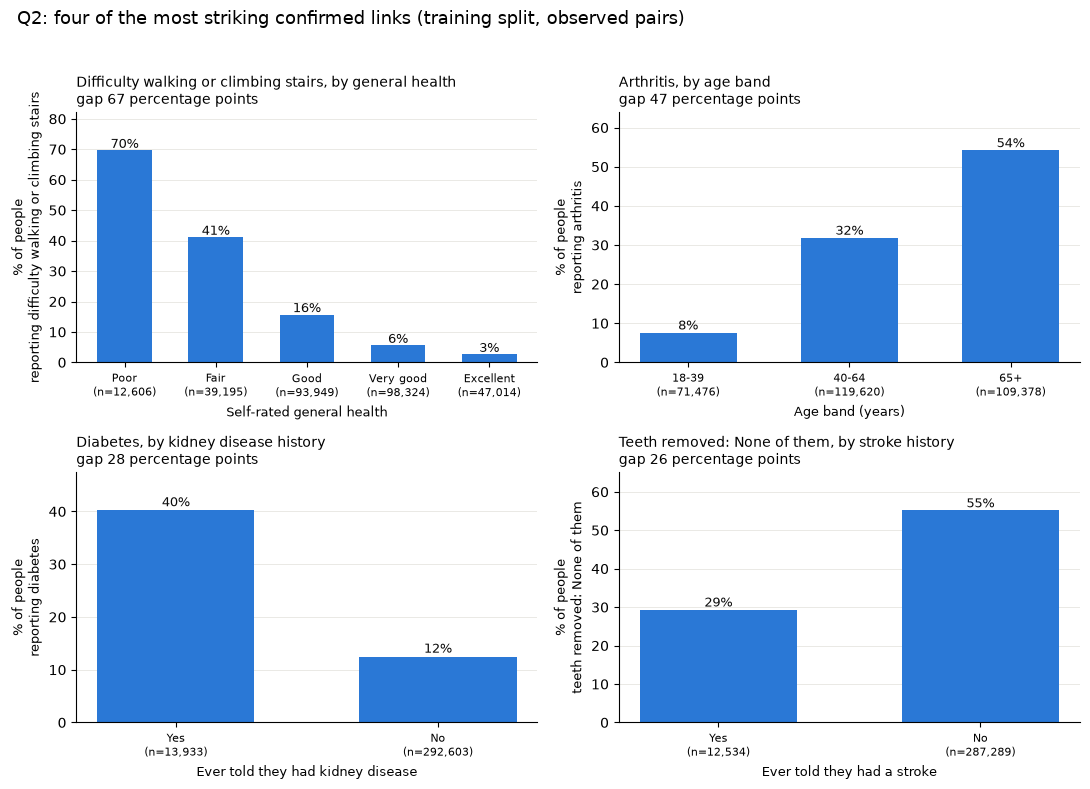

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, row in zip(axes.flat, FIG2.itertuples()):
    data = shares.loc[(shares["predictor"] == row.predictor) & (shares["candidate"] == row.candidate)
                      & (shares["candidate_level_or_stat"] == row.candidate_level_or_stat)]
    data = data.set_index("predictor_level").reindex(LEVEL_ORDER[row.predictor])
    ax.bar(range(len(data)), data["value"], color=BLUE, width=0.6)
    for i, (value, n) in enumerate(zip(data["value"], data["n"])):
        ax.text(i, value + 0.8, f"{value:.0f}%", ha="center", fontsize=9, color=INK)
    ax.set_xticks(range(len(data)), [f"{lvl}\n(n={n:,})" for lvl, n in zip(data.index, data["n"])], fontsize=8)
    level = row.candidate_level_or_stat.replace(" (%)", "")
    what = plain(row.candidate) if level == "Yes" else f"{plain(row.candidate)}: {level}"
    ax.set_ylabel("% of people\n" + ("reporting " if level == "Yes" else "") + what, fontsize=9)
    ax.set_xlabel(plain(row.predictor), fontsize=9)
    ax.set_title(f"{what[0].upper() + what[1:]}, by {SHORT_PREDICTOR[row.predictor]}\n"
                 f"gap {row.gap_pp:.0f} percentage points", loc="left", fontsize=10)
    ax.set_ylim(0, max(data["value"]) * 1.18)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Q2: four of the most striking confirmed links (training split, observed pairs)", x=0.02, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG_DIR / "q02_link_examples.png", dpi=150, bbox_inches="tight")
plt.show()

**Outcome (section E):** The 25 confirmed links give 142 profile rows (`results/q2/q2_link_profiles.csv`). Figure 1 shows every top link in the confirmed colour. Figure 2 applies the rule (largest gaps, State excluded, no repeated predictor or candidate):

- GeneralHealth × DifficultyWalking: 69.7% (poor) vs 2.6% (excellent), a 67-point gap;
- AgeCategory × HadArthritis: 7.6% at 18–39 vs 54.2% at 65+, a 47-point gap;
- HadKidneyDisease × HadDiabetes: 40.2% vs 12.4% "Yes", a 28-point gap;
- HadStroke × RemovedTeeth: 29.4% of people with a stroke still have all their teeth, compared with 55.2% without, a 26-point gap.

HadStroke × DifficultyWalking (46.0% vs 14.6%, 31 points) and HadKidneyDisease × DifficultyWalking (42.7% vs 14.6%, 28 points) were skipped only because difficulty walking is already shown in the general-health panel. Of the two new AgeCategory links, difficulty walking rises from 3.7% (18–39) to 25.4% (65+), and skin cancer from 0.7% to 16.3%. Sex's largest gap is 10.7 points (depression), so Sex did not make the figure.

## Section F: Q2 summary

**AgeCategory.** The answers that differ most between age groups are arthritis, testing and vaccination. Arthritis is reported by 54.2% of people aged 65+, 31.8% at 40–64 and 7.6% at 18–39. Ever having had an HIV test falls from 42.1% (18–39) to 18.1% (65+), while a flu vaccine in the past year rises from 35.1% to 69.9%. Skin cancer (0.7% → 16.3%) and difficulty walking (3.7% → 25.4%) also rise steeply across the same bands.

**GeneralHealth.** Self-rated health goes together most closely with day-to-day function. People who rated their health as poor reported a median of 30 bad physical-health days in the past month, compared with 0 for those rating it good or better; difficulty walking is reported by 69.7% of people in poor health and 2.6% of people in excellent health. Difficulty with errands (44.8% vs 1.6%) and with dressing or bathing (31.0% vs 0.6%) follow the same gradient, and the median number of bad mental-health days is 10 in poor health and 0 in good or better health.

**Sex.** Differences between men and women are small (all V ≤ 0.132). The largest is depression: 25.6% of women report a depressive disorder, compared with 14.9% of men. Women are more likely to have had a check-up in the past year (83.7% vs 76.5%) and to report arthritis (38.6% vs 29.1%), while men are more likely to report drinking alcohol in the past 30 days (58.5% vs 48.2%).

**HadStroke.** Among people who reported a stroke, 46.0% also reported difficulty walking, compared with 14.6% of people without a stroke. They were more likely to rate their health as fair or poor (45.8% vs 16.5%) and to be 65 or older (63.8% vs 35.1%), and 17.0% had all their teeth removed compared with 5.3%. They also reported more bad physical-health days (mean 10.0 vs 4.1; median 3 vs 0). GeneralHealth and difficulty walking are equally strong links; their intervals overlap.

**HadKidneyDisease.** Among people who reported kidney disease, 40.2% also reported diabetes, compared with 12.4% of people without kidney disease. 42.7% reported difficulty walking (vs 14.6%) and 46.7% rated their health as fair or poor (vs 16.3%); 63.6% were 65 or older (vs 35.0%). They also reported more bad physical-health days (mean 10.0 vs 4.0).

**Limits.**
- The analysis is unweighted: it describes this survey sample, not the population.
- The survey is a single point in time, so it cannot show which answer came first.
- V and eta measure the strength of a link only, not its direction; the profiles above show the direction.